In [ ]:

import pandas as pd
import numpy as np
# Load the loan prediction dataset
df = pd.read_csv("loan_prediction_dataset.csv.arff.csv")

# Display the first 5 records
print("First 5 records:")
print(df.head())

# Display the number of rows and columns
print("\nDataset shape:")
print(df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()


First 5 records:
  Gender Married Dependents       Education Self_Employed ApplicantIncome  \
0   Male      No          0        Graduate            No               ?   
1   Male     Yes          1        Graduate            No            4583   
2      ?     Yes          0        Graduate           Yes            3000   
3   Male     Yes          0  'Not Graduate'            No            2583   
4   Male      No          0        Graduate            No            6000   

  CoapplicantIncome LoanAmount Loan_Amount_Term Credit_History Property_Area  \
0                 0          ?              360              1         Urban   
1              1508        128              360              1         Rural   
2                 0         66              360              1             ?   
3              2358        120              360              1             ?   
4                 0        141              360              1         Urban   

  Loan_Status  
0           Y  
1      

In [ ]:
# Replace ? with null values
df.replace("?", np.nan, inplace=True)

# Count null values in each column
print("Null values in each column:")
print(df.isnull().sum())

Null values in each column:
Gender                64
Married               71
Dependents            69
Education             56
Self_Employed         93
ApplicantIncome       57
CoapplicantIncome     59
LoanAmount            86
Loan_Amount_Term      82
Credit_History       104
Property_Area         71
Loan_Status            0
dtype: int64


In [ ]:
# 2. Count duplicate rows
duplicates = df.duplicated().sum()
print("\nNumber of duplicate rows:", duplicates)

# 3. Display duplicate rows
print("\nDuplicate rows:")
print(df[df.duplicated()])



Number of duplicate rows: 0

Duplicate rows:
Empty DataFrame
Columns: [Gender, Married, Dependents, Education, Self_Employed, ApplicantIncome, CoapplicantIncome, LoanAmount, Loan_Amount_Term, Credit_History, Property_Area, Loan_Status]
Index: []


In [ ]:
# 4. Identify numerical and categorical columns
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(exclude=np.number).columns

# 5. Fill numerical null values with mean
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

# 6. Fill categorical null values with mode
for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])


In [ ]:
# Count null values in each column
print("Null values in each column:")
print(df.isnull().sum())

Null values in each column:
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [ ]:

# Numerical columns in the loan prediction dataset
numeric_cols = [
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History"
]

total_outliers = 0

print("Number of outliers in each column:\n")

for col in numeric_cols:
    if col in df.columns:
        values = pd.to_numeric(df[col], errors="coerce").dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = ((values < lower) | (values > upper)).sum()

        print(f"{col}: {outliers}")
        total_outliers += outliers

print("\nTotal outlier occurrences across columns:", total_outliers)

Number of outliers in each column:

ApplicantIncome: 51
CoapplicantIncome: 22
LoanAmount: 53
Loan_Amount_Term: 80
Credit_History: 83

Total outlier occurrences across columns: 289


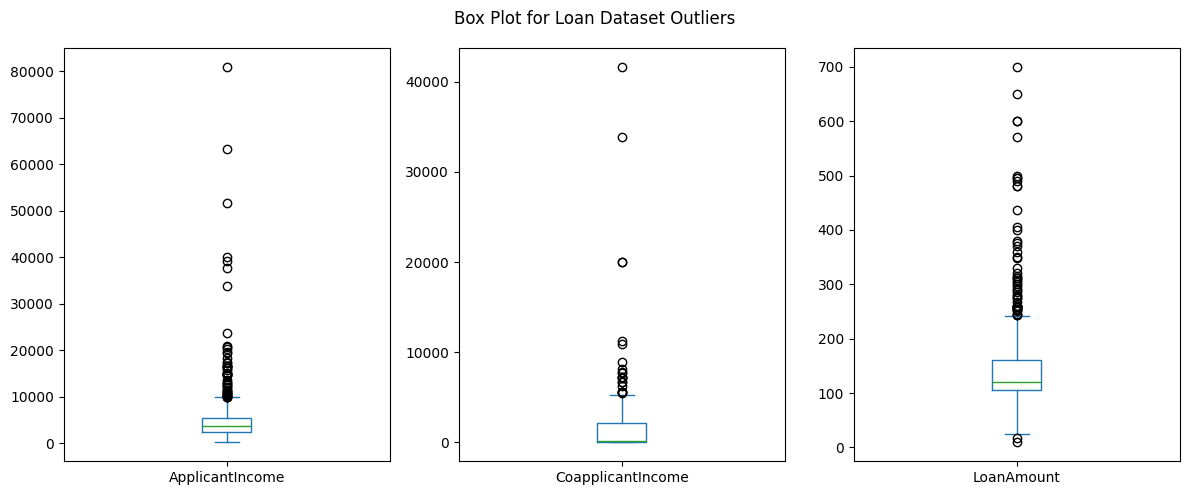

In [ ]:
import matplotlib.pyplot as plt
cols = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[cols].plot(
    kind="box",
    subplots=True,
    layout=(1, 3),
    figsize=(12, 5),
    sharey=False
)

plt.suptitle("Box Plot for Loan Dataset Outliers")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder
# Identify categorical columns
categorical_cols = df.select_dtypes(include=["object"]).columns

# Encode categorical columns
encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    encoders[col] = le

# Display encoded dataset
print("Encoded Dataset:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

# Save encoded dataset
df.to_csv("loan_prediction_encoded.csv", index=False)

print("\nEncoded dataset saved successfully!")

Encoded Dataset:
   Gender  Married  Dependents  Education  Self_Employed  ApplicantIncome  \
0       1        0           0          1              0             2500   
1       1        1           1          1              0             4583   
2       1        1           0          1              1             3000   
3       1        1           0          0              0             2583   
4       1        0           0          1              0             6000   

   CoapplicantIncome  LoanAmount  Loan_Amount_Term  Credit_History  \
0                0.0         120                 6               1   
1             1508.0         128                 6               1   
2                0.0          66                 6               1   
3             2358.0         120                 6               1   
4                0.0         141                 6               1   

   Property_Area  Loan_Status  
0              2            1  
1              0            0  
2  

In [ ]:
from sklearn.model_selection import train_test_split
# Separate input features and target column
X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Total dataset:", len(df))
print("Training data:", len(X_train))
print("Testing data:", len(X_test))

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


Total dataset: 614
Training data: 491
Testing data: 123

X_train shape: (491, 11)
X_test shape: (123, 11)
y_train shape: (491,)
y_test shape: (123,)



===== LOGISTIC REGRESSION EVALUATION =====
Overall Accuracy : 86.18%
Precision        : 0.8760
Recall           : 0.8618
F1-Score         : 0.8504

Confusion Matrix:
[[22 16]
 [ 1 84]]


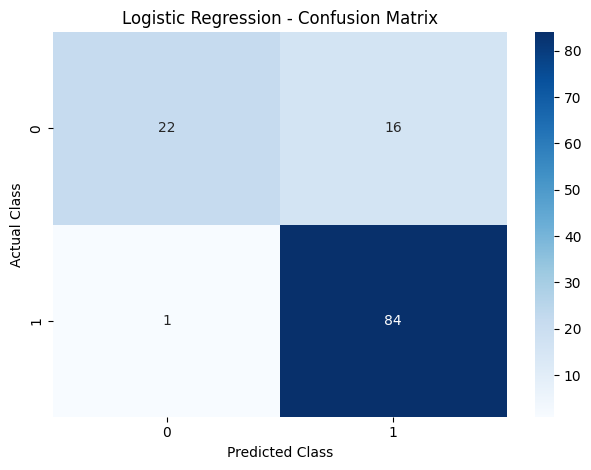


Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


FINAL OVERALL ALGORITHM ACCURACY: 86.18%


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Load the encoded dataset
df = pd.read_csv("loan_prediction_encoded.csv")

# 2. Remove rows with missing target values
df = df.dropna(subset=["Loan_Status"])

# 3. Separate features and target
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"].astype(int)

# 4. Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Create the Logistic Regression model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# 6. Train the model
model.fit(X_train, y_train)

# 7. Predict test results
y_pred = model.predict(X_test)

# 8. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred) * 100
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# 9. Print overall evaluation results
print("\n===== LOGISTIC REGRESSION EVALUATION =====")
print(f"Overall Accuracy : {accuracy:.2f}%")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"F1-Score         : {f1:.4f}")

# 10. Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# 11. Plot confusion matrix
class_labels = model.named_steps["logisticregression"].classes_

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# 12. Print classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

print(f"\nFINAL OVERALL ALGORITHM ACCURACY: {accuracy:.2f}%")



===== DECISION TREE EVALUATION =====
Overall Accuracy : 83.74%
Precision        : 0.8427
Recall           : 0.8374
F1-Score         : 0.8252

Confusion Matrix:
[[21 17]
 [ 3 82]]


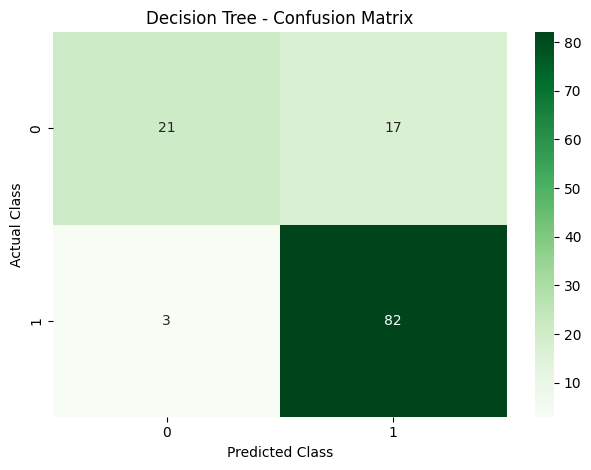


Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.55      0.68        38
           1       0.83      0.96      0.89        85

    accuracy                           0.84       123
   macro avg       0.85      0.76      0.78       123
weighted avg       0.84      0.84      0.83       123


FINAL ALGORITHM ACCURACY: 83.74%


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Load the encoded dataset
df = pd.read_csv("loan_prediction_encoded.csv")

# 2. Remove rows with missing target values
df = df.dropna(subset=["Loan_Status"])

# 3. Separate input features and target
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"].astype(int)

# 4. Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Create Decision Tree model
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# 6. Train the model
model.fit(X_train, y_train)

# 7. Predict test results
y_pred = model.predict(X_test)

# 8. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred) * 100

precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# 9. Print evaluation results
print("\n===== DECISION TREE EVALUATION =====")
print(f"Overall Accuracy : {accuracy:.2f}%")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"F1-Score         : {f1:.4f}")

# 10. Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# 11. Plot confusion matrix
class_labels = model.classes_

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# 12. Print classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# 13. Final overall accuracy
print("\n======================================")
print(f"FINAL ALGORITHM ACCURACY: {accuracy:.2f}%")
print("======================================")



===== RANDOM FOREST EVALUATION =====
Overall Accuracy : 84.55%
Precision        : 0.8438
Recall           : 0.8455
F1-Score         : 0.8390

Confusion Matrix:
[[24 14]
 [ 5 80]]


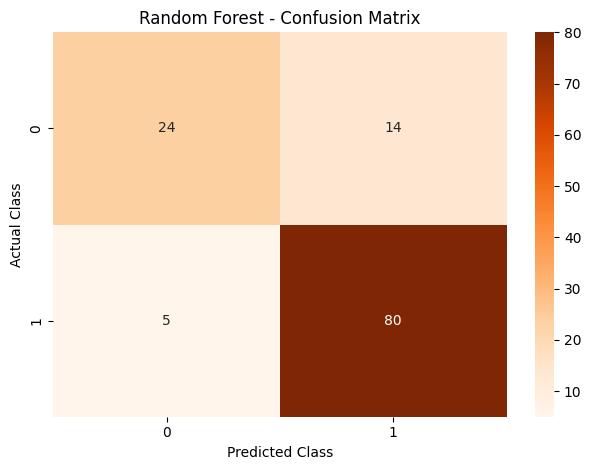


Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.63      0.72        38
           1       0.85      0.94      0.89        85

    accuracy                           0.85       123
   macro avg       0.84      0.79      0.81       123
weighted avg       0.84      0.85      0.84       123


FINAL ALGORITHM ACCURACY: 84.55%


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Load the encoded dataset
df = pd.read_csv("loan_prediction_encoded.csv")

# 2. Remove rows with missing target values
df = df.dropna(subset=["Loan_Status"])

# 3. Separate input features and target
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"].astype(int)

# 4. Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Create Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    random_state=42
)

# 6. Train the model
model.fit(X_train, y_train)

# 7. Predict test results
y_pred = model.predict(X_test)

# 8. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred) * 100

precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

# 9. Print evaluation results
print("\n===== RANDOM FOREST EVALUATION =====")
print(f"Overall Accuracy : {accuracy:.2f}%")
print(f"Precision        : {precision:.4f}")
print(f"Recall           : {recall:.4f}")
print(f"F1-Score         : {f1:.4f}")

# 10. Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# 11. Plot confusion matrix
class_labels = model.classes_

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# 12. Print classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# 13. Final overall accuracy
print("\n======================================")
print(f"FINAL ALGORITHM ACCURACY: {accuracy:.2f}%")
print("======================================")



===== MODEL PERFORMANCE COMPARISON =====
              Model  Accuracy (%)  Precision  Recall  F1-Score
Logistic Regression         86.18     0.8760  0.8618    0.8504
      Decision Tree         83.74     0.8427  0.8374    0.8252
      Random Forest         84.55     0.8438  0.8455    0.8390

===== BEST MODEL BASED ON ACCURACY =====
Model: Logistic Regression
Accuracy: 86.18 %
Precision: 0.876
Recall: 0.8618
F1-Score: 0.8504


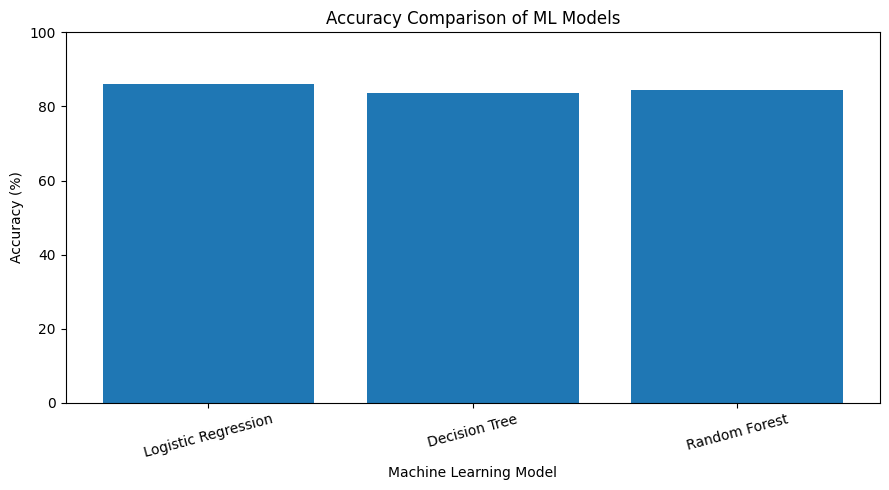

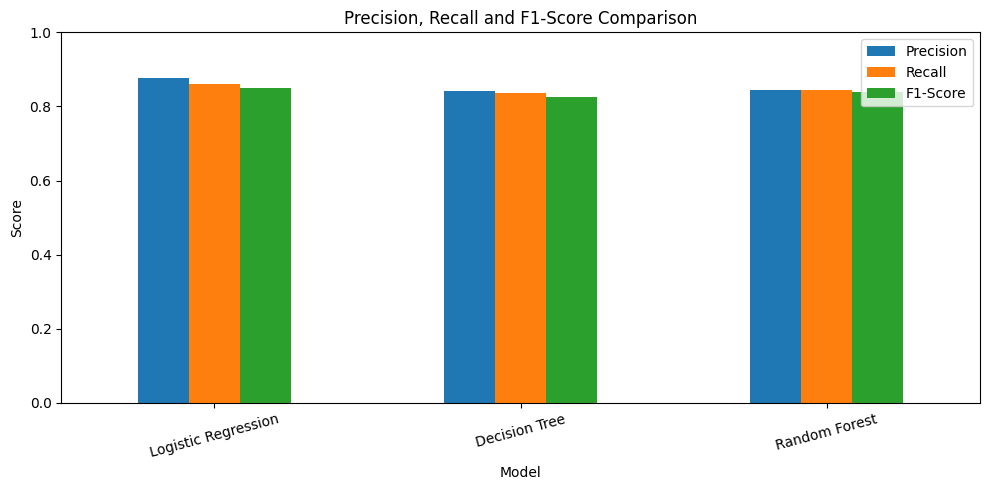

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Load dataset
df = pd.read_csv("loan_prediction_encoded.csv")

# 2. Remove rows with missing target values
df = df.dropna(subset=["Loan_Status"])

# 3. Separate features and target
X = df.drop(columns=["Loan_Status"])
y = df["Loan_Status"].astype(int)

# 4. Split dataset (same split for all models)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Define models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# 6. Train models and calculate metrics
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, y_pred) * 100, 2
        ),
        "Precision": round(
            precision_score(
                y_test, y_pred,
                average="weighted", zero_division=0
            ), 4
        ),
        "Recall": round(
            recall_score(
                y_test, y_pred,
                average="weighted", zero_division=0
            ), 4
        ),
        "F1-Score": round(
            f1_score(
                y_test, y_pred,
                average="weighted", zero_division=0
            ), 4
        )
    })

# 7. Display comparison table
results_df = pd.DataFrame(results)

print("\n===== MODEL PERFORMANCE COMPARISON =====")
print(results_df.to_string(index=False))

# 8. Find the model with the highest accuracy
best_model = results_df.loc[
    results_df["Accuracy (%)"].idxmax()
]

print("\n===== BEST MODEL BASED ON ACCURACY =====")
print("Model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy (%)"], "%")
print("Precision:", best_model["Precision"])
print("Recall:", best_model["Recall"])
print("F1-Score:", best_model["F1-Score"])

# 9. Plot accuracy comparison
plt.figure(figsize=(9, 5))
plt.bar(
    results_df["Model"],
    results_df["Accuracy (%)"]
)
plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 10. Plot precision, recall and F1-score comparison
results_df.set_index("Model")[
    ["Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Precision, Recall and F1-Score Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
